In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
import os
import sys
sys.path.append("../../")

import glob

In [3]:
microstructure_dir = "../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/"

summary = run_microstructure(
    folder=microstructure_dir,
    cores_per_task=10,
    save_full=True,
    verbose=True,
)

summary.keys()

dict_keys(['microstructure', 'version', 'taufactor', 'berg_voxel', 'berg_cc'])

In [4]:
porosity = summary["taufactor"]["porosity"]
phi_c = summary["berg_cc"]["phi_c"]

print(f"taufactor porosity: {porosity:.6f}")
print(f"berg_cc phi_c:      {phi_c:.6f}")
print(f"gap:                 {porosity - phi_c:.6f}")

taufactor porosity: 0.328073
berg_cc phi_c:      0.331040
gap:                 -0.002967


In [11]:
from pathlib import Path
import json
import numpy as np
import cache_utils

folder = Path(microstructure_dir).expanduser().resolve()

print("Resolved folder:", folder)
print("Manifest:")

manifest_path = folder / "manifest.json"
if manifest_path.exists():
    print(json.dumps(json.loads(manifest_path.read_text()), indent=2))
else:
    print("No manifest.json")

for filename in ["segmented_premesh.npy", "body_array.npy", "segmented_premesh.npy"]:
    path = folder / filename
    if path.exists():
        array = np.load(path)
        print(
            filename,
            "shape=", array.shape,
            "dtype=", array.dtype,
            "pore_fraction=", float((array == 3).mean()) if filename == "segmented_premesh.npy" else float((array > 0).mean()),
        )

print("Summary version:", summary["version"])

for method in ["taufactor", "berg_cc"]:
    resolved_version = summary[method]["_resolved_version"]
    result_dir = cache_utils.resolve_real_dir(
        folder,
        summary["version"],
        method,
    )
    print(method, "resolved version:", resolved_version)
    print(method, "result directory:", result_dir)
    print(
        "config:",
        json.dumps(
            json.loads((result_dir / "config.json").read_text()),
            indent=2,
        ),
    )

Resolved folder: /Users/rochan/Downloads/Rochan/Research/Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3
Manifest:
No manifest.json
segmented_premesh.npy shape= (150, 150, 150) dtype= uint8 pore_fraction= 0.42638696296296297
body_array.npy shape= (150, 150, 150) dtype= int32 pore_fraction= 0.42638696296296297
segmented_premesh.npy shape= (150, 150, 150) dtype= uint8 pore_fraction= 0.42638696296296297
Summary version: 1
taufactor resolved version: 1
taufactor result directory: /Users/rochan/Downloads/Rochan/Research/Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/version1/taufactor
config: {
  "phase_id": 1,
  "axis": 0,
  "segmented_file": "segmented.npy"
}
berg_cc resolved version: 1
berg_cc result directory: /Users/rochan/Downloads/Rochan/Research/Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/version1/berg_cc
c

In [5]:
import glob

files = glob.glob(f"{microstructure_dir}/*.npy", recursive=True)

NameError: name 'microstructure_dir' is not defined

In [9]:
files

['../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/body_array.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/segmented_premesh_2.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/body_array_2.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/segmented_premesh.npy']

In [6]:
microstructure_dir = "../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/"
files = glob.glob(f"{microstructure_dir}/**/segmented.npy", recursive=True)

In [19]:
from pqdm.threads import pqdm
from mesh_utils import percolated_phase

In [25]:
sorted(files)

['../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_0/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_1/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_2/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_3/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_4/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_5/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_6/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data

In [26]:
percolated = []
for i in sorted(files):
    percolated.append({i: percolated_phase(np.load(i),axis=0,resample=False)})

Isolated phase removal done

Voxels set to 0 (excluded from mesh): 278919 (8.3% of domain)
  Phase 1: 1415532 voxels (41.9%)
  Phase 2: 784312 voxels (23.2%)
  Phase 3: 896237 voxels (26.6%)
Isolated phase removal done

Voxels set to 0 (excluded from mesh): 309829 (9.2% of domain)
  Phase 1: 1294347 voxels (38.4%)
  Phase 2: 721151 voxels (21.4%)
  Phase 3: 1049673 voxels (31.1%)
Isolated phase removal done

Voxels set to 0 (excluded from mesh): 852139 (25.2% of domain)
  Phase 1: 1428730 voxels (42.3%)
  Phase 2: 695402 voxels (20.6%)
  Phase 3: 398729 voxels (11.8%)
Isolated phase removal done

Voxels set to 0 (excluded from mesh): 1164010 (34.5% of domain)
  Phase 1: 1336270 voxels (39.6%)
  Phase 2: 874720 voxels (25.9%)
  Phase 3: 0 voxels (0.0%)
Isolated phase removal done

Voxels set to 0 (excluded from mesh): 1072980 (31.8% of domain)
  Phase 1: 1403251 voxels (41.6%)
  Phase 2: 779180 voxels (23.1%)
  Phase 3: 119589 voxels (3.5%)
Isolated phase removal done

Voxels set to 0 (

In [32]:
os.path.dirname(files[0])

'../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Fine_microstructure_3'

In [33]:
files

['../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Fine_microstructure_3/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Fine_microstructure_4/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Fine_microstructure_5/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Fine_microstructure_2/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_4/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Medium_microstructure_3/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_SOFC_NiYSZ_Exp/Selected_Microstructures/Coarse_microstructure_4/segmented.npy',
 '../../../../Constrictivity/Microstructure_Data/Holzer_

In [35]:
from pathlib import Path
import numpy as np
import shutil

out_root = Path("../../data_new")
out_root.mkdir(parents=True, exist_ok=True)

n_written = 0
for entry in percolated:
    for src_path, perc_arr in entry.items():
        src_path = Path(src_path)
        ms_name = src_path.parent.name
        ms_dir = out_root / ms_name
        ms_dir.mkdir(parents=True, exist_ok=True)

        # original, untouched segmented array
        shutil.copy2(src_path, ms_dir / "segmented.npy")

        # premesh output
        np.save(ms_dir / "segmented_percolated.npy", perc_arr)

        print(f"{ms_name}: original copied, percolated {perc_arr.shape} dtype={perc_arr.dtype} saved")
        n_written += 1

print(f"\nWrote {n_written} microstructures to {out_root.resolve()}")

Coarse_microstructure_0: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_1: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_2: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_3: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_4: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_5: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_6: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_7: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_8: original copied, percolated (150, 150, 150) dtype=uint8 saved
Coarse_microstructure_9: original copied, percolated (150, 150, 150) dtype=uint8 saved
Fine_microstructure_0: original copied, percolated (150, 150, 150) dtype=uint8 saved
Fine_microstructure_1: original copied, perco

## SNOW

In [36]:
import imageio
import matplotlib.pyplot as plt
import numpy as np
import openpnm as op
import scipy.ndimage as spim
from skimage.segmentation import watershed

import porespy as ps
from porespy.filters import find_peaks, trim_nearby_peaks, trim_saddle_points
from porespy.tools import randomize_colors

ps.settings.tqdm["disable"] = True
ps.visualization.set_mpl_style()
np.random.seed(10)

import pandas as pd
import sys

In [46]:
fine_files = sorted(glob.glob(f"../../data_new/Fine*/segmented_percolated.npy", recursive=True))
medium_files = sorted(glob.glob(f"../../data_new/Medium*/segmented_percolated.npy", recursive=True))
coarse_files = sorted(glob.glob(f"../../data_new/Coarse*/segmented_percolated.npy", recursive=True))

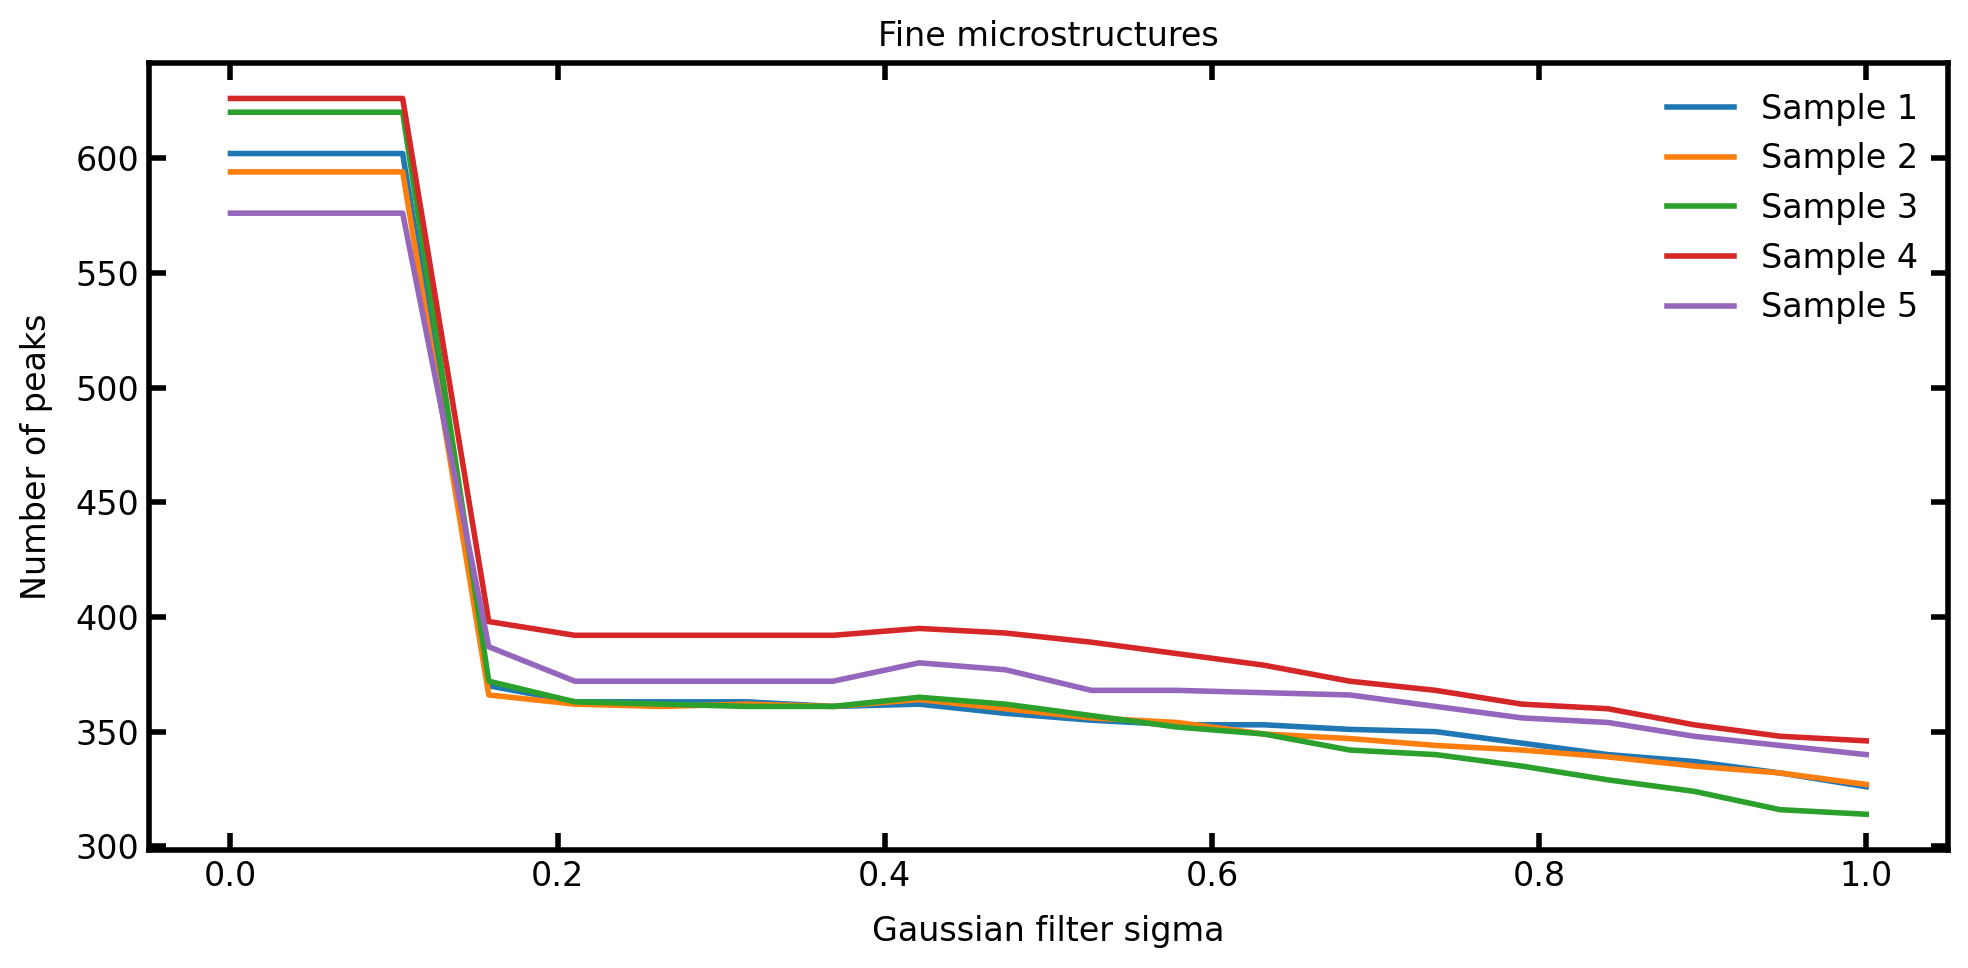

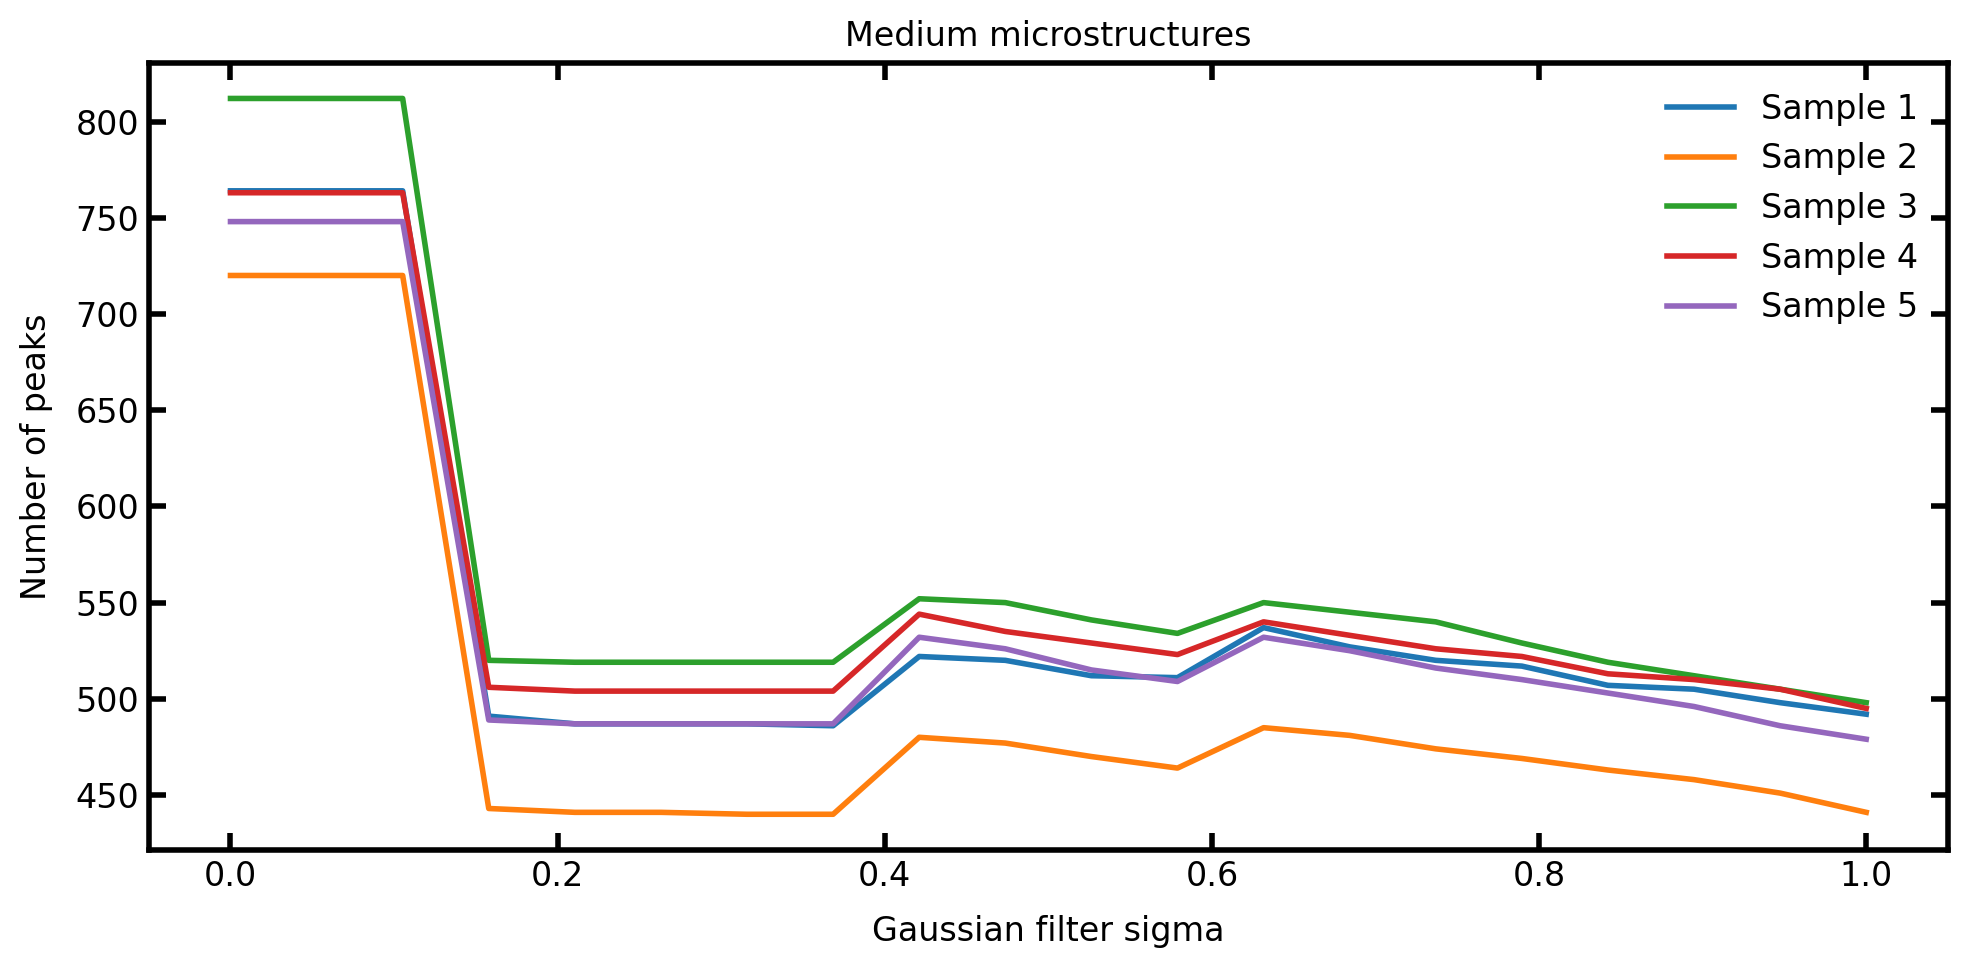

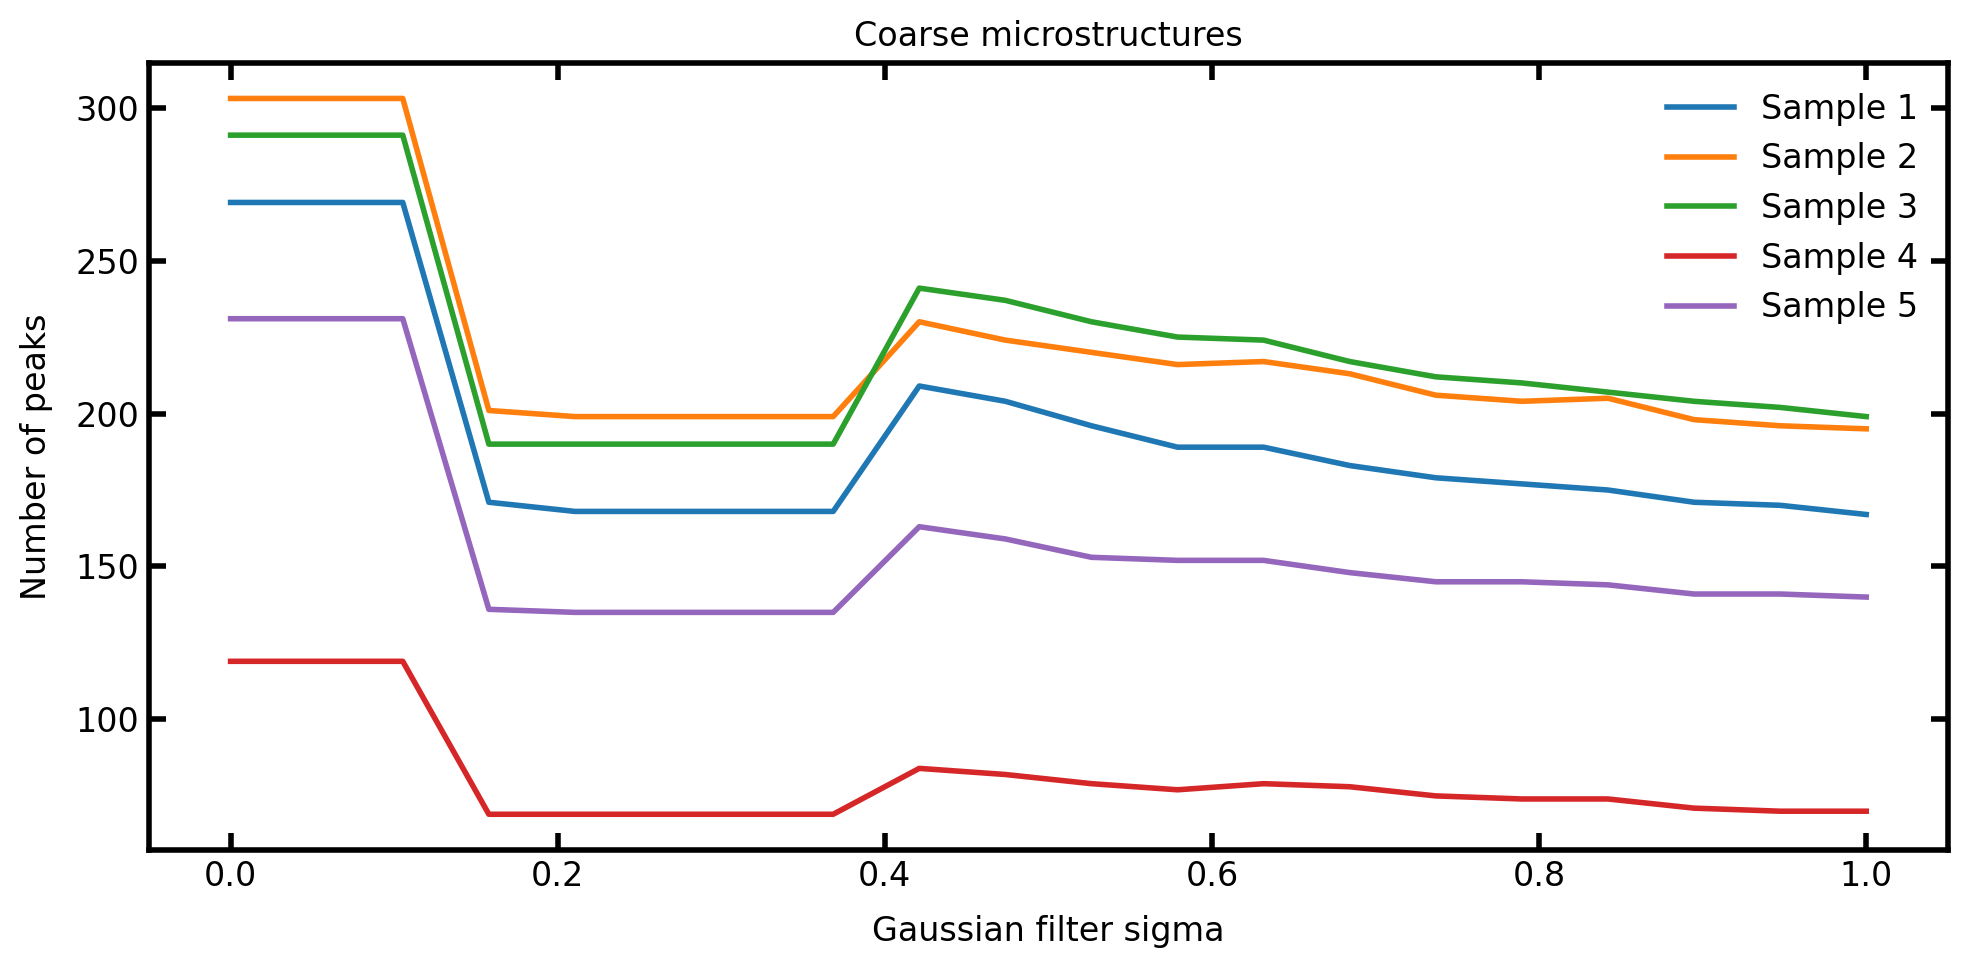

In [53]:
for i,k in zip([fine_files, medium_files, coarse_files], ['Fine', 'Medium', 'Coarse']):
    N = 5
    choices = np.random.choice(i, size=N, replace=False)
    all_peaks = []
    for h,j in enumerate(choices):
        im = (np.load(j) == 3).astype(bool)
        local_peaks = []
        ranges = np.linspace(0,1,20)

        for sigma in ranges:
            dt = spim.distance_transform_edt(input=im)
            dt1 = spim.gaussian_filter(input=dt, sigma=sigma)
            peaks = find_peaks(dt=dt1)
            local_peaks.append(spim.label(peaks)[1])

        all_peaks.append(local_peaks)

    plt.figure(figsize=(10,5))
    for h in range(N):
        plt.plot(ranges, all_peaks[h],label=f"Sample {h+1}")
    plt.xlabel('Gaussian filter sigma')
    plt.ylabel('Number of peaks')
    plt.title(f'{k} microstructures')
    plt.legend()
    plt.show()

In [55]:
import particulate_claude as pc

In [57]:
i = fine_files[0]

Initial number of peaks:  521
Peaks after trimming saddle points:  407
Peaks after trimming nearby peaks:  335
  Iteration 1: 22 boundary-only bodies
  Iteration 2: 0 boundary-only bodies

Iterative boundary merge complete:
  Total iterations         : 1
  Total bodies merged      : 22
  Distinct bodies before   : 335
  Distinct bodies after    : 313
  Pore voxels before       : 1574004
  Pore voxels after        : 1574004  (should be same)
  Iteration 1: merged 3 bodies → [251, 298, 302]

Short-circuit merge complete:
  Total iterations       : 1
  Total bodies merged    : 3
  Distinct bodies before : 313
  Distinct bodies after  : 310
  Pore voxels before     : 1574004
  Pore voxels after      : 1574004  (should be same)


ValueError: not enough values to unpack (expected 3, got 2)

In [61]:
for i in sorted(fine_files + medium_files + coarse_files):
    axis = 0
    verbose = True
    microstructure = np.load(i)
    im = (microstructure==3).astype(bool)

    sigma = 0.20
    dt = spim.distance_transform_edt(input=im)
    dt1 = spim.gaussian_filter(input=dt, sigma=sigma)
    peaks = find_peaks(dt=dt)

    print("Initial number of peaks: ", spim.label(peaks)[1])
    peaks = trim_saddle_points(peaks=peaks, dt=dt1)
    print("Peaks after trimming saddle points: ", spim.label(peaks)[1])
    peaks = trim_nearby_peaks(peaks=peaks, dt=dt)
    peaks, N = spim.label(peaks)
    print("Peaks after trimming nearby peaks: ", N)

    regions = watershed(image=-dt, markers=peaks, mask=dt > 0)
    berg_body = regions
    body_array, _, _ = pc.merge_boundary_only_bodies_iterative(berg_body, axis=axis, verbose=verbose)
    body_array, _ = pc.merge_short_circuit_bodies(body_array, axis=axis, verbose=verbose)
    print("Number of bodies after merging: ", len(np.unique(body_array)))
    body_array = regions
    np.save(f"{os.path.dirname(i)}/body_array.npy", body_array)

Initial number of peaks:  291
Peaks after trimming saddle points:  230
Peaks after trimming nearby peaks:  195
  Iteration 1: 19 boundary-only bodies
  Iteration 2: 0 boundary-only bodies

Iterative boundary merge complete:
  Total iterations         : 1
  Total bodies merged      : 19
  Distinct bodies before   : 195
  Distinct bodies after    : 176
  Pore voxels before       : 896237
  Pore voxels after        : 896237  (should be same)
  Iteration 1: merged 2 bodies → [20, 105]

Short-circuit merge complete:
  Total iterations       : 1
  Total bodies merged    : 2
  Distinct bodies before : 176
  Distinct bodies after  : 174
  Pore voxels before     : 896237
  Pore voxels after      : 896237  (should be same)
Number of bodies after merging:  175
Initial number of peaks:  269
Peaks after trimming saddle points:  210
Peaks after trimming nearby peaks:  181
  Iteration 1: 9 boundary-only bodies
  Iteration 2: 0 boundary-only bodies

Iterative boundary merge complete:
  Total iteration